# AE No-RL for DNP3

This notebook adapts the original AE-RL (Adversarial Environment + Reinforcement Learning) setup from NSL-KDD to a more recent IDS dataset (default: **DNP3**), but runs a **no-RL baseline** where **both agents are standard DNN classifiers**.

**Key changes vs. the original notebook**
- Dataset: DNP3 (optionally extendable to other tabular IDS datasets).
- Agents: **Attacker = DNN** (predicts fine-grained label), **Defender = DNN** (predicts coarse attack type).
- Explainability: optional **SAGE** global feature importance for the defender.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from keras.models import Sequential
from keras.layers import Dense
from keras import optimizers
from keras import backend as K
import json
from sklearn.utils import shuffle
import os
import sys
import time

In [2]:
# Optional: install explainability libraries (run if needed)
# !pip -q install shap sage-importance

import warnings
warnings.filterwarnings('ignore')


In [3]:
# ----------------------------
# Dataset wrapper (DNP3 Intrusion Detection Dataset)
# ----------------------------
# Expected raw data: either a single CSV file OR a folder of CSVs.
# (Common CSV schema includes a "Label" column for the attack name.)
#
# Notes:
# - Drops obvious identifier columns (Flow ID, IPs, Timestamp, MACs, etc.).
# - Low-cardinality categorical columns are one-hot encoded; high-cardinality ones are dropped.
# - Produces a formatted CSV with [scaled features] + [one-hot fine labels].

import os
import json
from glob import glob

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle


def _label_to_type(label: str) -> str:
    """Map DNP3 fine label -> coarse defender label."""
    s = str(label).strip().lower()

    if s in {"benign", "normal", "0", "no_attack", "no attack"} or "benign" in s or "normal" in s:
        return "BENIGN"
    if "mitm" in s:
        return "MITM_DoS"
    if "replay" in s:
        return "Replay"
    if "enumerate" in s or "info" in s:
        return "Recon"
    if ("disable" in s or "unsolicited" in s or "restart" in s or "stop" in s or
        "initial" in s or "initialize" in s or "warm" in s or "cold" in s):
        return "Command"
    if "dos" in s or "denial" in s:
        return "DoS"
    return "OtherAttack"


def _looks_like_id_column(col: str) -> bool:
    c = str(col).strip().lower()
    return any(k in c for k in [
        "flow id", "timestamp", "src ip", "dst ip", "source ip", "destination ip",
        "src mac", "dst mac", "frame src", "frame dst",
        "uid", "session", "uuid"
    ])

def _pick_label_column(df: pd.DataFrame, preferred: str = "Label") -> str:
    if preferred in df.columns:
        return preferred
    low = {c.lower(): c for c in df.columns}
    for cand in ["label", "class", "attack", "category", "target", "type"]:
        if cand in low:
            return low[cand]
    raise ValueError("Could not find a label column. Tried: Label, label/class/attack/category/target/type")

def _encode_features(df: pd.DataFrame, drop_cols, max_cardinality: int = 50) -> pd.DataFrame:
    X = df.drop(columns=list(drop_cols), errors="ignore").copy()

    # Drop identifier-like columns
    id_cols = [c for c in X.columns if _looks_like_id_column(c)]
    if len(id_cols) > 0:
        X.drop(columns=id_cols, inplace=True, errors="ignore")

    # Split categorical vs numeric
    obj_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

    # Keep low-card categorical columns; drop high-card (IPs, hashes, etc.)
    low_card = [c for c in obj_cols if X[c].nunique(dropna=True) <= max_cardinality]
    high_card = [c for c in obj_cols if c not in low_card]
    if len(high_card) > 0:
        X.drop(columns=high_card, inplace=True, errors="ignore")

    if len(low_card) > 0:
        X = pd.get_dummies(X, columns=low_card, dummy_na=True)

    # Convert to numeric + clean
    X = X.apply(pd.to_numeric, errors="coerce")
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(0.0, inplace=True)

    # Drop constant columns
    nunq = X.nunique(dropna=False)
    const_cols = nunq[nunq <= 1].index.tolist()
    if len(const_cols) > 0:
        X.drop(columns=const_cols, inplace=True, errors="ignore")

    return X

class data_cls:
    def __init__(self, train_test, **kwargs):
        self.train_test = train_test
        self.dataset = kwargs.get("dataset", "dnp3")

        # Paths
        self.data_dir = kwargs.get("data_dir", r"C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/dnp3/")
        self.formated_train_path = kwargs.get("formated_train_path", "formated_train_dnp3_adv.csv")
        self.formated_test_path  = kwargs.get("formated_test_path",  "formated_test_dnp3_adv.csv")

        # Options
        self.test_size = kwargs.get("test_size", 0.2)
        self.random_state = kwargs.get("random_state", 42)
        self.force_reformat = kwargs.get("force_reformat", False)
        self.include_benign = kwargs.get("include_benign", True)

        # Populated after formatting/loading
        self.attack_names = []
        self.all_attack_names = []
        self.attack_types = []
        self.attack_map = {}

    def _meta_path(self, formatted_path: str) -> str:
        return formatted_path + ".meta.json"

    def _try_load_meta(self, formatted_path: str) -> bool:
        meta_p = self._meta_path(formatted_path)
        if os.path.exists(meta_p):
            with open(meta_p, "r", encoding="utf-8") as f:
                meta = json.load(f)
            self.all_attack_names = meta["all_attack_names"]
            self.attack_names = meta["attack_names"]
            self.attack_types = meta["attack_types"]
            self.attack_map = meta["attack_map"]
            return True
        return False

    def _save_meta(self, formatted_path: str):
        meta = {
            "dataset": self.dataset,
            "all_attack_names": self.all_attack_names,
            "attack_names": self.attack_names,
            "attack_types": self.attack_types,
            "attack_map": self.attack_map,
        }
        with open(self._meta_path(formatted_path), "w", encoding="utf-8") as f:
            json.dump(meta, f, indent=2)

    def _load_raw(self) -> pd.DataFrame:
        # data_dir can be a directory OR a single CSV file path
        if os.path.isfile(self.data_dir) and self.data_dir.lower().endswith(".csv"):
            csv_files = [self.data_dir]
        else:
            csv_files = sorted(glob(os.path.join(self.data_dir, "**", "*.csv"), recursive=True))

        if len(csv_files) == 0:
            raise FileNotFoundError(
                "No CSVs found at data_dir='" + str(self.data_dir) + "'.\n"
                "Fix: set data_dir to a CSV file path or a folder that contains CSVs."
            )

        dfs = []
        for fp in csv_files:
            try:
                dfs.append(pd.read_csv(fp, low_memory=False))
            except Exception as e:
                print("[WARN] Skipping unreadable CSV:", fp, "(", e, ")")

        if len(dfs) == 0:
            raise FileNotFoundError("No readable CSVs were found.")

        return pd.concat(dfs, ignore_index=True)

    def _ensure_formatted(self):
        train_ok = os.path.exists(self.formated_train_path)
        test_ok  = os.path.exists(self.formated_test_path)

        if (not self.force_reformat) and train_ok and test_ok:
            if self._try_load_meta(self.formated_train_path):
                return

        df = self._load_raw()
        label_col = _pick_label_column(df, preferred="Label")

        y_fine = df[label_col].astype(str).str.strip()
        y_coarse = y_fine.map(_label_to_type)

        if not self.include_benign:
            keep = y_coarse != "BENIGN"
            df = df.loc[keep].reset_index(drop=True)
            y_fine = y_fine.loc[keep].reset_index(drop=True)

        X = _encode_features(df, drop_cols=[label_col])
        fine_labels = sorted(y_fine.unique().tolist())

        attack_map = {lbl: _label_to_type(lbl) for lbl in fine_labels}
        attack_types = []
        for lbl in fine_labels:
            t = attack_map[lbl]
            if t not in attack_types:
                attack_types.append(t)

        strat = y_fine if y_fine.nunique() > 1 else None
        X_train, X_test, y_train, y_test = train_test_split(
            X, y_fine, test_size=self.test_size, random_state=self.random_state, stratify=strat
        )

        scaler = StandardScaler()
        X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
        X_test_s  = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

        y_train_oh = pd.get_dummies(y_train, prefix="", prefix_sep="").reindex(columns=fine_labels, fill_value=0)
        y_test_oh  = pd.get_dummies(y_test,  prefix="", prefix_sep="").reindex(columns=fine_labels, fill_value=0)

        train_df = pd.concat([X_train_s.reset_index(drop=True), y_train_oh.reset_index(drop=True)], axis=1)
        test_df  = pd.concat([X_test_s.reset_index(drop=True),  y_test_oh.reset_index(drop=True)], axis=1)

        train_df.to_csv(self.formated_train_path, index=False)
        test_df.to_csv(self.formated_test_path, index=False)

        self.all_attack_names = fine_labels
        self.attack_names = fine_labels
        self.attack_types = attack_types
        self.attack_map = attack_map
        self._save_meta(self.formated_train_path)
        self._save_meta(self.formated_test_path)

    def _load_df(self):
        self._ensure_formatted()

        path = self.formated_train_path if self.train_test == "train" else self.formated_test_path
        self.df = pd.read_csv(path, low_memory=False)

        label_cols = [c for c in self.df.columns if c in self.all_attack_names]
        if len(label_cols) == 0:
            raise ValueError("Formatted file has no one-hot label columns. Re-run with force_reformat=True.")

        label_sums = self.df[label_cols].sum(axis=0)
        self.attack_names = [c for c in label_cols if label_sums.get(c, 0) > 0]

        self.df = shuffle(self.df, random_state=self.random_state).reset_index(drop=True)

    def get_shape(self):
        return self.df.shape

    def get_batch(self, batch_size=1):
        if batch_size == "full":
            batch_size = len(self.df)

        batch = self.df.sample(int(batch_size))
        labels = batch[self.attack_names]
        batch = batch.drop(columns=self.all_attack_names, errors="ignore")
        return batch, labels


In [4]:
# Huber loss function        
def huber_loss(y_true, y_pred, clip_value=1):
    # Huber loss, see https://en.wikipedia.org/wiki/Huber_loss and
    # https://medium.com/@karpathy/yes-you-should-understand-backprop-e2f06eab496b
    # for details.
    assert clip_value > 0.

    x = y_true - y_pred
    if np.isinf(clip_value):
        # Spacial case for infinity since Tensorflow does have problems
        # if we compare `K.abs(x) < np.inf`.
        return .5 * K.square(x)

    condition = K.abs(x) < clip_value
    squared_loss = .5 * K.square(x)
    linear_loss = clip_value * (K.abs(x) - .5 * clip_value)
    if K.backend() == 'tensorflow':
        import tensorflow as tf
        if hasattr(tf, 'select'):
            return tf.select(condition, squared_loss, linear_loss)  # condition, true, false
        else:
            return tf.where(condition, squared_loss, linear_loss)  # condition, true, false
    elif K.backend() == 'theano':
        from theano import tensor as T
        return T.switch(condition, squared_loss, linear_loss)
    else:
        raise RuntimeError('Unknown backend "{}".'.format(K.backend()))

# Needed for keras huber_loss locate
import keras.losses
keras.losses.huber_loss = huber_loss


In [5]:
class QNetwork():
    """
    Q-Network Estimator
    Represents the global model for the table
    """

    def __init__(self,obs_size,num_actions,hidden_size = 100,
                 hidden_layers = 1,learning_rate=.2):
        """
        Initialize the network with the provided shape
        """
        self.obs_size = obs_size
        self.num_actions = num_actions
        
        # Network arquitecture
        self.model = Sequential()
        # Add imput layer
        self.model.add(Dense(hidden_size, input_shape=(obs_size,),
                             activation='relu'))
        # Add hidden layers
        for layers in range(hidden_layers):
            self.model.add(Dense(hidden_size, activation='relu'))
        # Add output layer    
        self.model.add(Dense(num_actions))
        
        #optimizer = optimizers.SGD(learning_rate)
        # optimizer = optimizers.Adam(alpha=learning_rate)
        optimizer = optimizers.Adam(0.00025)
        # optimizer = optimizers.RMSpropGraves(learning_rate, 0.95, self.momentum, 1e-2)
        
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
            loss=keras.losses.Huber(delta=1),
        )

    def predict(self,state,batch_size=1):
        """
        Predicts action values.
        """
        return self.model.predict(state,batch_size=batch_size)

    def update(self, states, q):
        """
        Updates the estimator with the targets.

        Args:
          states: Target states
          q: Estimated values

        Returns:
          The calculated loss on the batch.
        """
        loss = self.model.train_on_batch(states, q)
        return loss
    
    def copy_model(model):
        """Returns a copy of a keras model."""
        model.save('tmp_model.keras')
        return keras.models.load_model('tmp_model.keras', custom_objects={"huber_loss": huber_loss})


In [6]:
#Policy interface
class Policy:
    def __init__(self, num_actions, estimator):
        self.num_actions = num_actions
        self.estimator = estimator
    
class Epsilon_greedy(Policy):
    def __init__(self,estimator ,num_actions ,epsilon,min_epsilon,decay_rate, epoch_length):
        Policy.__init__(self, num_actions, estimator)
        self.name = "Epsilon Greedy"
        
        if (epsilon is None or epsilon < 0 or epsilon > 1):
            print("EpsilonGreedy: Invalid value of epsilon", flush = True)
            sys.exit(0)
        self.epsilon = epsilon
        self.min_epsilon = min_epsilon
        self.actions = list(range(num_actions))
        self.step_counter = 0
        self.epoch_length = epoch_length
        self.decay_rate = decay_rate
        
        #if epsilon is up 0.1, it will be decayed over time
        if self.epsilon > 0.01:
            self.epsilon_decay = True
        else:
            self.epsilon_decay = False
    
    def get_actions(self,states):
        # get next action
        if np.random.rand() <= self.epsilon:
            actions = np.random.randint(0, self.num_actions,states.shape[0])
        else:
            self.Q = self.estimator.predict(states,states.shape[0])
            actions = []
            for row in range(self.Q.shape[0]):
                best_actions = np.argwhere(self.Q[row] == np.amax(self.Q[row]))
                actions.append(best_actions[np.random.choice(len(best_actions))].item())
            
        self.step_counter += 1 
        # decay epsilon after each epoch
        if self.epsilon_decay:
            if self.step_counter % self.epoch_length == 0:
                self.epsilon = max(self.min_epsilon, self.epsilon * self.decay_rate**self.step_counter)
            
        return actions

In [7]:
# class ReplayMemory(object):
#     """Implements basic replay memory"""

#     def __init__(self, observation_size, max_size):
#         self.observation_size = observation_size
#         self.num_observed = 0
#         self.max_size = max_size
#         self.samples = {
#                  'obs'      : np.zeros(self.max_size * 1 * self.observation_size,
#                                        dtype=np.float32).reshape(self.max_size,self.observation_size),
#                  'action'   : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
#                  'reward'   : np.zeros(self.max_size * 1).reshape(self.max_size, 1),
#                  'terminal' : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
#                }

#     # def observe(self, state, action, reward, done):
#     #     index = self.num_observed % self.max_size
#     #     self.samples['obs'][index, :] = state
#     #     self.samples['action'][index, :] = action
#     #     self.samples['reward'][index, :] = reward
#     #     self.samples['terminal'][index, :] = done

#     #     self.num_observed += 1

#     def observe(self, state, action, reward, done):
#             # Convert DataFrame -> ndarray
#         if isinstance(state, pd.DataFrame):
#             state = state.to_numpy()
    
#         state = np.asarray(state)
#         action = np.asarray(action)
    
#         # If batch of states, insert each transition
#         if state.ndim == 2:
#             n = state.shape[0]
    
#             # Make reward/done arrays length n
#             if np.isscalar(reward):
#                 reward = np.full((n,), reward, dtype=np.float32)
#             else:
#                 reward = np.asarray(reward).reshape(-1)
    
#             if np.isscalar(done):
#                 done = np.full((n,), done, dtype=np.float32)
#             else:
#                 done = np.asarray(done).reshape(-1)
    
#             # Make action length n (if scalar, repeat; if already length n, keep)
#             if action.ndim == 0:
#                 action = np.full((n,), action, dtype=np.int64)
#             else:
#                 action = action.reshape(-1)
    
#             # Push each row
#             for s, a, r, d in zip(state, action, reward, done):
#                 self.observe(s, a, r, d)
#             return
    
#     def sample_minibatch(self, minibatch_size):
#         max_index = min(self.num_observed, self.max_size) - 1
#         if max_index <= 0:
#             raise ValueError(f"Not enough samples to draw minibatch yet. num_observed={self.num_observed}")
    
#         sampled_indices = np.random.randint(0, max_index, size=minibatch_size)

#         s      = np.asarray(self.samples['obs'][sampled_indices, :], dtype=np.float32)
#         s_next = np.asarray(self.samples['obs'][sampled_indices+1, :], dtype=np.float32)

#         a      = self.samples['action'][sampled_indices].reshape(minibatch_size)
#         r      = self.samples['reward'][sampled_indices].reshape((minibatch_size, 1))
#         done   = self.samples['terminal'][sampled_indices].reshape((minibatch_size, 1))

#         return (s, a, r, s_next, done)

In [8]:
class ReplayMemory(object):
    """Replay memory storing full transitions: (s, a, r, s', done)."""

    def __init__(self, observation_size, max_size):
        self.observation_size = int(observation_size)
        self.max_size = int(max_size)
        self.num_observed = 0

        self.samples = {
            "obs":      np.zeros((self.max_size, self.observation_size), dtype=np.float32),
            "next_obs": np.zeros((self.max_size, self.observation_size), dtype=np.float32),
            "action":   np.zeros((self.max_size, 1), dtype=np.int16),
            "reward":   np.zeros((self.max_size, 1), dtype=np.float32),
            "terminal": np.zeros((self.max_size, 1), dtype=np.int16),
        }

    def _to_2d_state(self, x):
        # DataFrame -> ndarray
        if isinstance(x, pd.DataFrame):
            x = x.to_numpy()
        x = np.asarray(x, dtype=np.float32)
        if x.ndim == 1:
            x = x.reshape(1, -1)
        return x

    def _to_1d(self, x):
        x = np.asarray(x)
        if x.ndim == 0:
            return x.reshape(1)
        return x.reshape(-1)

    def observe(self, state, action, reward, next_state, done):
        """
        Accepts single OR batched transitions.
        state / next_state can be (obs,), (N, obs) or pd.DataFrame.
        action can be scalar or (N,)
        reward can be scalar or (N,) or (N,1)
        done can be scalar or (N,) or (N,1)
        """
        s  = self._to_2d_state(state)
        ns = self._to_2d_state(next_state)

        if s.shape[1] != self.observation_size or ns.shape[1] != self.observation_size:
            raise ValueError(
                f"obs_size mismatch: expected {self.observation_size}, got {s.shape[1]} and {ns.shape[1]}"
            )

        n = s.shape[0]

        a = self._to_1d(action)
        r = self._to_1d(reward)
        d = self._to_1d(done)

        # Broadcast scalars / singletons to batch length n if needed
        if a.size == 1 and n > 1:
            a = np.full((n,), int(a[0]), dtype=np.int64)
        if r.size == 1 and n > 1:
            r = np.full((n,), float(r[0]), dtype=np.float32)
        if d.size == 1 and n > 1:
            d = np.full((n,), int(d[0]), dtype=np.int64)

        # Final sanity check
        if a.shape[0] != n or r.shape[0] != n or d.shape[0] != n:
            raise ValueError(f"Batch length mismatch: n={n}, action={a.shape}, reward={r.shape}, done={d.shape}")

        # Insert each row as its own transition
        for i in range(n):
            idx = self.num_observed % self.max_size
            self.samples["obs"][idx, :]      = s[i]
            self.samples["next_obs"][idx, :] = ns[i]
            self.samples["action"][idx, 0]   = int(a[i])
            self.samples["reward"][idx, 0]   = float(r[i])
            self.samples["terminal"][idx, 0] = int(d[i])
            self.num_observed += 1

    def sample_minibatch(self, minibatch_size):
        available = min(self.num_observed, self.max_size)
        if available < minibatch_size:
            raise ValueError(
                f"Not enough samples to draw minibatch yet. "
                f"num_observed={self.num_observed}, available={available}, minibatch_size={minibatch_size}"
            )

        sampled_indices = np.random.randint(0, available, size=minibatch_size)

        s      = self.samples["obs"][sampled_indices, :].astype(np.float32)
        s_next = self.samples["next_obs"][sampled_indices, :].astype(np.float32)

        a    = self.samples["action"][sampled_indices].reshape(minibatch_size)          # (mb,)
        r    = self.samples["reward"][sampled_indices].reshape((minibatch_size, 1))     # (mb,1)
        done = self.samples["terminal"][sampled_indices].reshape((minibatch_size, 1))   # (mb,1)

        return (s, a, r, s_next, done)

In [9]:
'''
Reinforcement learning Agent definition
'''

class Agent(object):  
        
    def __init__(self, actions,obs_size, policy="EpsilonGreedy", **kwargs):
        self.actions = actions
        self.num_actions = len(actions)
        self.obs_size = obs_size
        
        self.epsilon = kwargs.get('epsilon', 1)
        self.min_epsilon = kwargs.get('min_epsilon', .1)
        self.gamma = kwargs.get('gamma', .001)
        self.minibatch_size = kwargs.get('minibatch_size', 2)
        self.epoch_length = kwargs.get('epoch_length', 100)
        self.decay_rate = kwargs.get('decay_rate',0.99)
        self.ExpRep = kwargs.get('ExpRep',True)
        if self.ExpRep:
            self.memory = ReplayMemory(self.obs_size, kwargs.get('mem_size', 10))
            #self.memory = ReplayMemory(self.mem_size, self.obs_size)
        
        self.ddqn_time = 100
        self.ddqn_update = self.ddqn_time

        
        self.model_network = QNetwork(self.obs_size, self.num_actions,
                                      kwargs.get('hidden_size', 100),
                                      kwargs.get('hidden_layers',1),
                                      kwargs.get('learning_rate',.2))
        self.target_model_network = QNetwork(self.obs_size, self.num_actions,
                                      kwargs.get('hidden_size', 100),
                                      kwargs.get('hidden_layers',1),
                                      kwargs.get('learning_rate',.2))
        self.target_model_network.model = QNetwork.copy_model(self.model_network.model)
        
        if policy == "EpsilonGreedy":
            self.policy = Epsilon_greedy(self.model_network,len(actions),
                                         self.epsilon,self.min_epsilon,
                                         self.decay_rate,self.epoch_length)
        
        
    def learn(self, states, actions, next_states, rewards, done):
        if self.ExpRep:
            # NOTE: now we store full transitions (s, a, r, s', done)
            self.memory.observe(states, actions, rewards, next_states, done)
        else:
            self.states = states
            self.actions = actions
            self.rewards = rewards
            self.next_states = next_states
            self.done = done
            
    def update_model(self):
        if self.ExpRep:
            (states, actions, rewards, next_states, done) = self.memory.sample_minibatch(self.minibatch_size)
        else:
            states = self.states
            rewards = self.rewards
            next_states = self.next_states
            actions = self.actions
            done = self.done
        
        next_actions = []
        # Compute Q targets
#        Q_prime = self.model_network.predict(next_states,self.minibatch_size)
        Q_prime = self.target_model_network.predict(next_states,self.minibatch_size)
        # TODO: fix performance in this loop
        for row in range(Q_prime.shape[0]):
            best_next_actions = np.argwhere(Q_prime[row] == np.amax(Q_prime[row]))
            next_actions.append(best_next_actions[np.random.choice(len(best_next_actions))].item())
        sx = np.arange(len(next_actions))
        # Compute Q(s,a)
        Q = self.model_network.predict(states,self.minibatch_size)
        # Q-learning update
        # target = reward + gamma * max_a'{Q(next_state,next_action))}
        targets = rewards.reshape(Q[sx,actions].shape) + \
                  self.gamma * Q[sx,next_actions] * \
                  (1-done.reshape(Q[sx,actions].shape))   
        Q[sx,actions] = targets  
        
        loss = self.model_network.model.train_on_batch(states,Q)#inputs,targets        
        
        # timer to ddqn update
        self.ddqn_update -= 1
        if self.ddqn_update == 0:
            self.ddqn_update = self.ddqn_time
#            self.target_model_network.model = QNetwork.copy_model(self.model_network.model)
            self.target_model_network.model.set_weights(self.model_network.model.get_weights()) 
        
        return loss    

    def act(self, state,policy):
        raise NotImplementedError

In [10]:
# ----------------------------
# Agents (No-RL baseline)
# ----------------------------
# Defender: Deep Neural Network (supervised) -> predicts coarse attack type
# Attacker: Deep Neural Network (supervised) -> predicts fine-grained attack label

import json
import numpy as np
from keras.utils import to_categorical

class DefenderDNN(object):
    def __init__(self, obs_size, n_classes, **kwargs):
        self.obs_size = int(obs_size)
        self.n_classes = int(n_classes)
        self.hidden_size = int(kwargs.get('hidden_size', 128))
        self.hidden_layers = int(kwargs.get('hidden_layers', 2))
        self.learning_rate = float(kwargs.get('learning_rate', 1e-3))

        self.model = Sequential()
        self.model.add(Dense(self.hidden_size, input_dim=self.obs_size, activation='relu'))
        for _ in range(max(0, self.hidden_layers - 1)):
            self.model.add(Dense(self.hidden_size, activation='relu'))
        self.model.add(Dense(self.n_classes, activation='softmax'))

        opt = optimizers.Adam(learning_rate=self.learning_rate)
        self.model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

    def _ensure_onehot(self, y):
        y = np.asarray(y)
        if y.ndim == 2 and y.shape[1] == self.n_classes:
            return y.astype(np.float32)
        # assume integer class indices
        y = y.reshape(-1)
        return to_categorical(y, num_classes=self.n_classes).astype(np.float32)

    def fit(self, X_train, y_train, X_val=None, y_val=None, **kwargs):
        X_train = np.asarray(X_train, dtype=np.float32)
        y_train_oh = self._ensure_onehot(y_train)

        val_data = None
        if X_val is not None and y_val is not None:
            X_val = np.asarray(X_val, dtype=np.float32)
            y_val_oh = self._ensure_onehot(y_val)
            val_data = (X_val, y_val_oh)

        epochs = int(kwargs.get('epochs', 5))
        batch_size = int(kwargs.get('batch_size', 1024))
        verbose = int(kwargs.get('verbose', 0))

        return self.model.fit(
            X_train, y_train_oh,
            validation_data=val_data,
            epochs=epochs,
            batch_size=batch_size,
            verbose=verbose
        )

    def act(self, states):
        # states: pd.DataFrame or np.ndarray
        X = states.values if hasattr(states, 'values') else states
        X = np.asarray(X, dtype=np.float32)
        probs = self.model.predict(X, verbose=0)
        return np.argmax(probs, axis=1)

    def save(self, json_path, weights_path):
        self.model.save_weights(weights_path, overwrite=True)
        with open(json_path, 'w') as f:
            json.dump(self.model.to_json(), f)

    @staticmethod
    def load(json_path, weights_path, **kwargs):
        from keras.models import model_from_json
        with open(json_path, 'r') as f:
            model = model_from_json(json.load(f))
        model.load_weights(weights_path)
        # compile for inference / SHAP / SAGE
        opt = optimizers.Adam(learning_rate=float(kwargs.get('learning_rate', 1e-3)))
        model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
        obj = DefenderDNN(obs_size=1, n_classes=1)  # dummy, will overwrite
        obj.model = model
        return obj


# Reuse the same wrapper for the attacker
AttackerDNN = DefenderDNN


In [11]:
'''
Reinforcement learning Enviroment Definition
'''
class RLenv(data_cls):
    def __init__(self,train_test,**kwargs):
        data_cls.__init__(self,train_test,**kwargs)
        data_cls._load_df(self)
        self.data_shape = data_cls.get_shape(self)
        self.batch_size = kwargs.get('batch_size',1) # experience replay -> batch = 1
        self.iterations_episode = kwargs.get('iterations_episode',10)
        if self.batch_size=='full':
            self.batch_size = int(self.data_shape[0]/iterations_episode)


    '''
    _update_state: function to update the current state
    Returns:
        None
    Modifies the self parameters involved in the state:
        self.state and self.labels
    Also modifies the true labels to get learning knowledge
    '''
    def _update_state(self):        
        self.states,self.labels = data_cls.get_batch(self)
        
        # Update statistics
        self.true_labels += np.sum(self.labels).values

    '''
    Returns:
        + Observation of the enviroment
    '''
    def reset(self):
        # Statistics
        self.def_true_labels = np.zeros(len(self.attack_types),dtype=int)
        self.def_estimated_labels = np.zeros(len(self.attack_types),dtype=int)
        self.att_true_labels = np.zeros(len(self.attack_names),dtype=int)
        
        self.state_numb = 0
        
        data_cls._load_df(self) # Reload and random index
        self.states,self.labels = data_cls.get_batch(self,self.batch_size)
        
        self.total_reward = 0
        self.steps_in_episode = 0
        return self.states 
   
    '''
    Returns:
        State: Next state for the game
        Reward: Actual reward
        done: If the game ends (no end in this case)
    
    In the adversarial enviroment, it's only needed to return the actual reward
    '''    
    def act(self,defender_actions,attack_actions):
        # Clear previous rewards        
        self.att_reward = np.zeros(len(attack_actions))       
        self.def_reward = np.zeros(len(defender_actions))
        
        
        attack = [self.attack_types.index(self.attack_map[self.attack_names[att]]) for att in attack_actions]
        
        self.def_reward = (np.asarray(defender_actions)==np.asarray(attack))*1
        self.att_reward = (np.asarray(defender_actions)!=np.asarray(attack))*1

         
       
        self.def_estimated_labels += np.bincount(defender_actions,minlength=len(self.attack_types))
        # TODO
        # list comprehension
        
        for act in attack_actions:
            self.def_true_labels[self.attack_types.index(self.attack_map[self.attack_names[act]])] += 1
        

        # Get new state and new true values 
        attack_actions = attacker_agent.act(self.states)
        self.states = env.get_states(attack_actions)
        
        # Done allways false in this continuous task       
        self.done = np.zeros(len(attack_actions),dtype=bool)
            
        return self.states, self.def_reward,self.att_reward, attack_actions, self.done
    
    '''
    Provide the actual states for the selected attacker actions
    Parameters:
        self:
        attacker_actions: optimum attacks selected by the attacker
            it can be one of attack_names list and select random of this
    Returns:
        State: Actual state for the selected attacks
    '''
    def get_states(self,attacker_actions):
        first = True
        for attack in attacker_actions:
            if first:
                minibatch = (self.df[self.df[self.attack_names[attack]]==1].sample(1))
                first = False
            else:
                minibatch = pd.concat(
                    [minibatch, self.df[self.df[self.attack_names[attack]] == 1].sample(1)],
                    ignore_index=True
                )
        
        self.labels = minibatch[self.attack_names]
        minibatch.drop(self.all_attack_names,axis=1,inplace=True)
        self.states = minibatch
        
        return self.states



In [12]:
if __name__ == "__main__":

    # ----------------------------
    # 1) Dataset configuration
    # ----------------------------
    # Put DNP3 CSV files in this folder, or change `data_dir`.
    data_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/dnp3/"

    formated_train_path = "formated_train_dnp3_adv.csv"
    formated_test_path  = "formated_test_dnp3_adv.csv"

    # AE loop settings (no RL)
    batch_size = 32
    iterations_episode = 100
    n_epochs = 60

    # ----------------------------
    # 1b) Create environment (TRAIN)
    # ----------------------------
    env = RLenv(
        'train',
        dataset='dnp3',
        data_dir=data_dir,
        formated_train_path=formated_train_path,
        formated_test_path=formated_test_path,
        batch_size=batch_size,
        iterations_episode=iterations_episode,
        include_benign=True,
        force_reformat=True,
        test_size=0.2,
        random_state=42
    )

    # obs_size = number of numeric feature columns
    obs_size = env.data_shape[1] - len(env.all_attack_names)

    print(f"Observation size: {obs_size}")
    print(f"Fine-grained attack labels (attacker output): {len(env.attack_names)}")
    print(f"Coarse attack types (defender output): {len(env.attack_types)} -> {env.attack_types}")

    # ----------------------------
    # 2) Build supervised datasets
    # ----------------------------
    df_train = pd.read_csv(formated_train_path)
    X_train_df = df_train.drop(env.all_attack_names, axis=1)
    X_train = X_train_df.to_numpy(dtype=np.float32)

    # Fine labels for attacker (indices aligned to env.attack_names order)
    y_fine = np.argmax(df_train[env.attack_names].to_numpy(), axis=1).astype(int)

    # Coarse labels for defender (map fine label -> coarse type -> index)
    fine_names = np.array(env.attack_names)
    fine_lbls = fine_names[y_fine]
    y_coarse = np.array([env.attack_types.index(env.attack_map[lbl]) for lbl in fine_lbls], dtype=int)

    # Split (kept for possible explainability background selection)
    X_tr, X_val, yfine_tr, yfine_val, ycoarse_tr, ycoarse_val = train_test_split(
        X_train, y_fine, y_coarse,
        test_size=0.2,
        random_state=42,
        stratify=y_coarse
    )

    # ----------------------------
    # 3) Initialize both DNN agents (no RL)
    # ----------------------------
    attacker_dnn = AttackerDNN(
        obs_size=obs_size,
        n_classes=len(env.attack_names),
        hidden_size=128,
        hidden_layers=2,
        learning_rate=1e-3
    )

    defender_dnn = DefenderDNN(
        obs_size=obs_size,
        n_classes=len(env.attack_types),
        hidden_size=128,
        hidden_layers=2,
        learning_rate=1e-3
    )

    # ----------------------------
    # 4) No-RL adversarial loop
    #    - Optionally do a tiny supervised update each epoch (train_on_batch)
    #    - Then run an episode where attacker selects attacks and defender predicts coarse types
    # ----------------------------
    def_reward_chain = []
    att_reward_chain = []
    def_loss_chain = []
    att_loss_chain = []
    attacks_by_epoch = []

    # small minibatch for quick per-epoch supervised refresh (set to 0 to disable)
    supervised_batch = min(2048, X_tr.shape[0])

    for epoch in range(n_epochs):
        # ---- tiny supervised refresh ----
        if supervised_batch > 0:
            idx = np.random.choice(X_tr.shape[0], size=supervised_batch, replace=False)

            att_loss, _ = attacker_dnn.model.train_on_batch(
                X_tr[idx],
                to_categorical(yfine_tr[idx], num_classes=len(env.attack_names)).astype(np.float32)
            )

            def_loss, _ = defender_dnn.model.train_on_batch(
                X_tr[idx],
                to_categorical(ycoarse_tr[idx], num_classes=len(env.attack_types)).astype(np.float32)
            )
        else:
            att_loss, def_loss = 0.0, 0.0

        # ---- episode simulation (no learning) ----
        def_total_reward_by_episode = 0
        att_total_reward_by_episode = 0

        states = env.reset()  # pd.DataFrame of features

        # attacker chooses fine-grained attacks for each row
        attack_actions = attacker_dnn.act(states)
        states = env.get_states(attack_actions)

        attacks_list = []

        for i_iteration in range(iterations_episode):
            attacks_list.append(int(np.asarray(attack_actions)[0]))

            # defender predicts coarse type
            defender_actions = defender_dnn.act(states)

            # true coarse type implied by the attack action chosen
            true_attack = np.array(
                [env.attack_types.index(env.attack_map[env.attack_names[int(a)]]) for a in np.asarray(attack_actions)],
                dtype=int
            )

            def_reward = (np.asarray(defender_actions) == true_attack).astype(int)
            att_reward = (np.asarray(defender_actions) != true_attack).astype(int)

            def_total_reward_by_episode += int(np.sum(def_reward))
            att_total_reward_by_episode += int(np.sum(att_reward))

            # next step: attacker picks again from current state; environment samples next state
            attack_actions = attacker_dnn.act(states)
            states = env.get_states(attack_actions)

        attacks_by_epoch.append(attacks_list)
        def_reward_chain.append(def_total_reward_by_episode)
        att_reward_chain.append(att_total_reward_by_episode)
        def_loss_chain.append(float(def_loss))
        att_loss_chain.append(float(att_loss))

        print(
            f"[Epoch {epoch}] def_reward={def_total_reward_by_episode} "
            f"att_reward={att_total_reward_by_episode} def_loss={def_loss:.4f} att_loss={att_loss:.4f}"
        )

    # ----------------------------
    # 5) Save models (for TEST + explainability reuse)
    # ----------------------------
    models_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_dnp3/"
    os.makedirs(models_dir, exist_ok=True)

    attacker_dnn.save(
        os.path.join(models_dir, "attacker_dnn_model_dnp3.json"),
        os.path.join(models_dir, "attacker_dnn_model_dnp3.weights.h5"),
    )

    defender_dnn.save(
        os.path.join(models_dir, "defender_dnn_model_dnp3.json"),
        os.path.join(models_dir, "defender_dnn_model_dnp3.weights.h5"),
    )


Observation size: 70
Fine-grained attack labels (attacker output): 11
Coarse attack types (defender output): 6 -> ['OtherAttack', 'Command', 'Recon', 'MITM_DoS', 'BENIGN', 'Replay']
[Epoch 0] def_reward=2217 att_reward=983 def_loss=1.6945 att_loss=2.4992
[Epoch 1] def_reward=2995 att_reward=205 def_loss=1.4633 att_loss=2.3424
[Epoch 2] def_reward=3153 att_reward=47 def_loss=1.2818 att_loss=2.1844
[Epoch 3] def_reward=3187 att_reward=13 def_loss=1.1353 att_loss=2.0662
[Epoch 4] def_reward=3184 att_reward=16 def_loss=0.9964 att_loss=1.9193
[Epoch 5] def_reward=3191 att_reward=9 def_loss=0.8838 att_loss=1.8330
[Epoch 6] def_reward=3174 att_reward=26 def_loss=0.8038 att_loss=1.7306
[Epoch 7] def_reward=3156 att_reward=44 def_loss=0.7365 att_loss=1.6500
[Epoch 8] def_reward=3153 att_reward=47 def_loss=0.6680 att_loss=1.6036
[Epoch 9] def_reward=3093 att_reward=107 def_loss=0.6176 att_loss=1.5287
[Epoch 10] def_reward=3067 att_reward=133 def_loss=0.5455 att_loss=1.4435
[Epoch 11] def_reward=

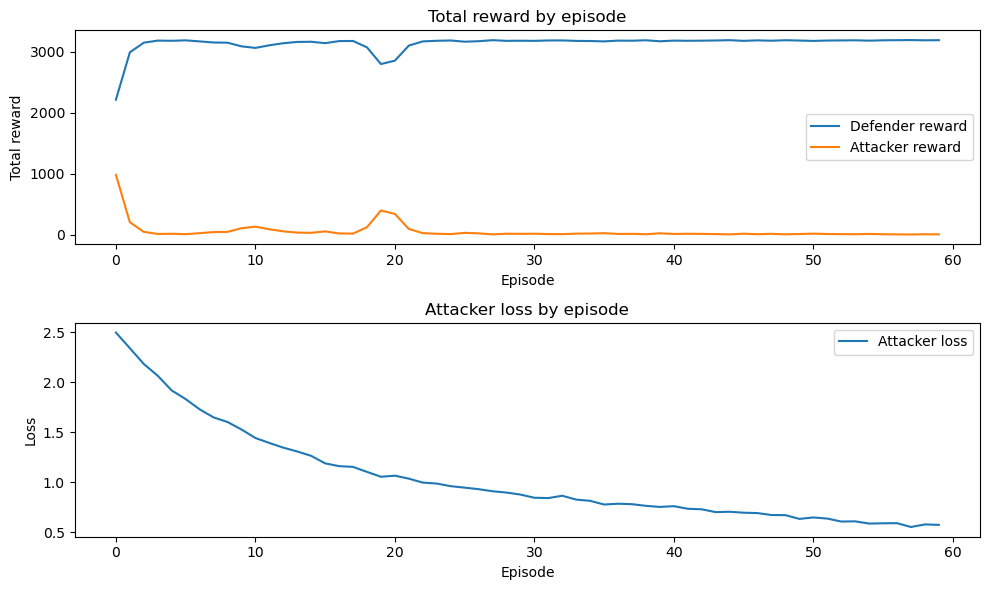

In [13]:
# ----------------------------
# Plot training curves
# ----------------------------
if not os.path.exists('results'):
    os.makedirs('results')

plt.figure(figsize=(10,6))
plt.subplot(211)
plt.plot(np.arange(len(def_reward_chain)), def_reward_chain, label='Defender reward')
plt.plot(np.arange(len(att_reward_chain)), att_reward_chain, label='Attacker reward')
plt.title('Total reward by episode')
plt.xlabel('Episode')
plt.ylabel('Total reward')
plt.legend()

plt.subplot(212)
plt.plot(np.arange(len(att_loss_chain)), att_loss_chain, label='Attacker loss')
plt.title('Attacker loss by episode')
plt.xlabel('Episode')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
#plt.savefig('results/train_adv_dnp3.png', dpi=300)
plt.show()


# Test and evaluation (DNP3)


In [14]:
from keras.models import model_from_json

import itertools
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import  confusion_matrix
from imblearn.metrics import geometric_mean_score

In [15]:

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')


In [25]:
# ----------------------------
# TEST (Defender DNN on DNP3 test split)
# ----------------------------
import os
import json
import numpy as np
import pandas as pd
from keras.models import model_from_json
from sklearn.metrics import classification_report, confusion_matrix

formated_test_path = "formated_test_dnp3_adv.csv"
data_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/dnp3/"
models_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_dnp3/"

# Define environment for test (must match the same formatted paths)
env_test = RLenv(
    'test',
    dataset='dnp3',
    data_dir=data_dir,
    formated_train_path="formated_train_dnp3_adv.csv",
    formated_test_path=formated_test_path,
    batch_size=64,
    iterations_episode=100,
    include_benign=True,
    force_reformat=True,
    test_size=0.2,
    random_state=42
)

# Load defender DNN
with open(os.path.join(models_dir, "defender_dnn_model_dnp3.json"), "r") as f:
    defender_json = json.load(f)

defender_dnn_model = model_from_json(defender_json)
defender_dnn_model.load_weights(os.path.join(models_dir, "defender_dnn_model_dnp3.weights.h5"))

# Pull full test set
states, labels = env_test.get_batch(batch_size=64)   # states: features; labels: fine-label one-hot columns

# True coarse labels
if labels.shape[0] == 0 or labels.shape[1] == 0:
    raise ValueError(f"Empty test labels: labels shape={labels.shape}. Check include_benign / available data files / formatted CSVs.")

fine_idx = np.argmax(labels.to_numpy(), axis=1)
fine_labels = labels.columns.to_numpy()[fine_idx]
coarse_labels = np.array([env_test.attack_map.get(lbl, _label_to_type(lbl)) for lbl in fine_labels])
y_true = np.array([env_test.attack_types.index(t) for t in coarse_labels], dtype=int)

# Predictions: greedy defense action = argmax(Q)
X = states.to_numpy(dtype=np.float32)
Q = defender_dnn_model.predict(X, verbose=0)
y_pred = np.argmax(Q, axis=1)

print("Attack types (classes):", env_test.attack_types)
print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=env_test.attack_types))

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion matrix:\n", cm)


Attack types (classes): ['OtherAttack', 'Command', 'Recon', 'MITM_DoS', 'BENIGN', 'Replay']

Classification report:

              precision    recall  f1-score   support

 OtherAttack       1.00      1.00      1.00        12
     Command       0.88      1.00      0.93        28
       Recon       1.00      1.00      1.00        11
    MITM_DoS       1.00      1.00      1.00         1
      BENIGN       1.00      0.29      0.44         7
      Replay       0.83      1.00      0.91         5

    accuracy                           0.92        64
   macro avg       0.95      0.88      0.88        64
weighted avg       0.93      0.92      0.90        64


Confusion matrix:
 [[12  0  0  0  0  0]
 [ 0 28  0  0  0  0]
 [ 0  0 11  0  0  0]
 [ 0  0  0  1  0  0]
 [ 0  4  0  0  2  1]
 [ 0  0  0  0  0  5]]


Confusion matrix, without normalization
[[12  0  0  0  0  0]
 [ 0 28  0  0  0  0]
 [ 0  0 11  0  0  0]
 [ 0  0  0  1  0  0]
 [ 0  4  0  0  2  1]
 [ 0  0  0  0  0  5]]


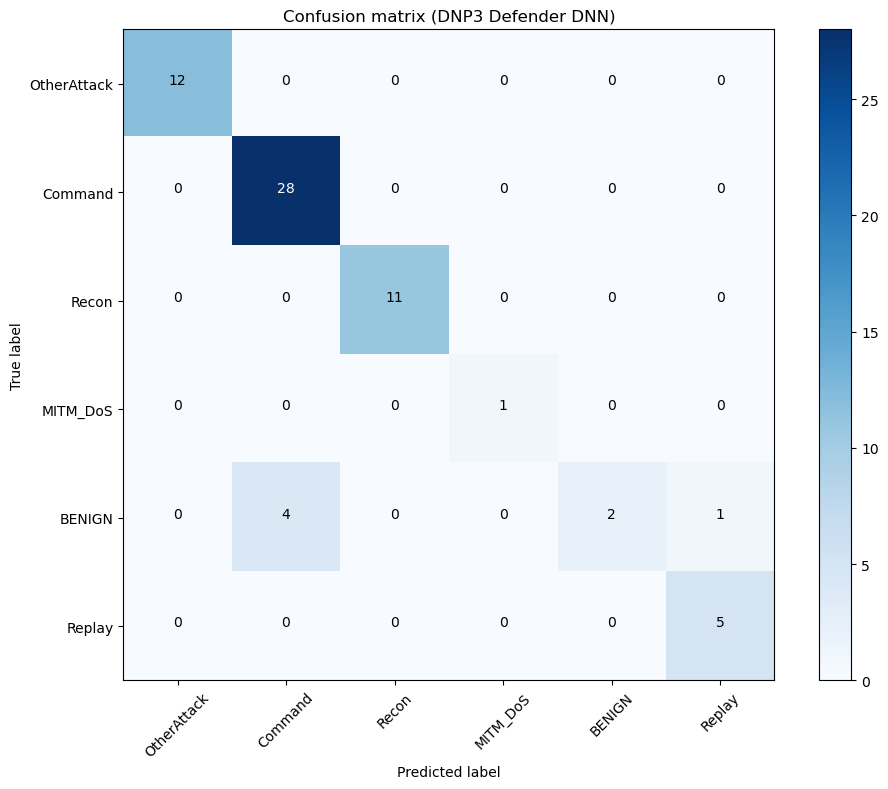

Normalized confusion matrix
[[1.         0.         0.         0.         0.         0.        ]
 [0.         1.         0.         0.         0.         0.        ]
 [0.         0.         1.         0.         0.         0.        ]
 [0.         0.         0.         1.         0.         0.        ]
 [0.         0.57142857 0.         0.         0.28571429 0.14285714]
 [0.         0.         0.         0.         0.         1.        ]]


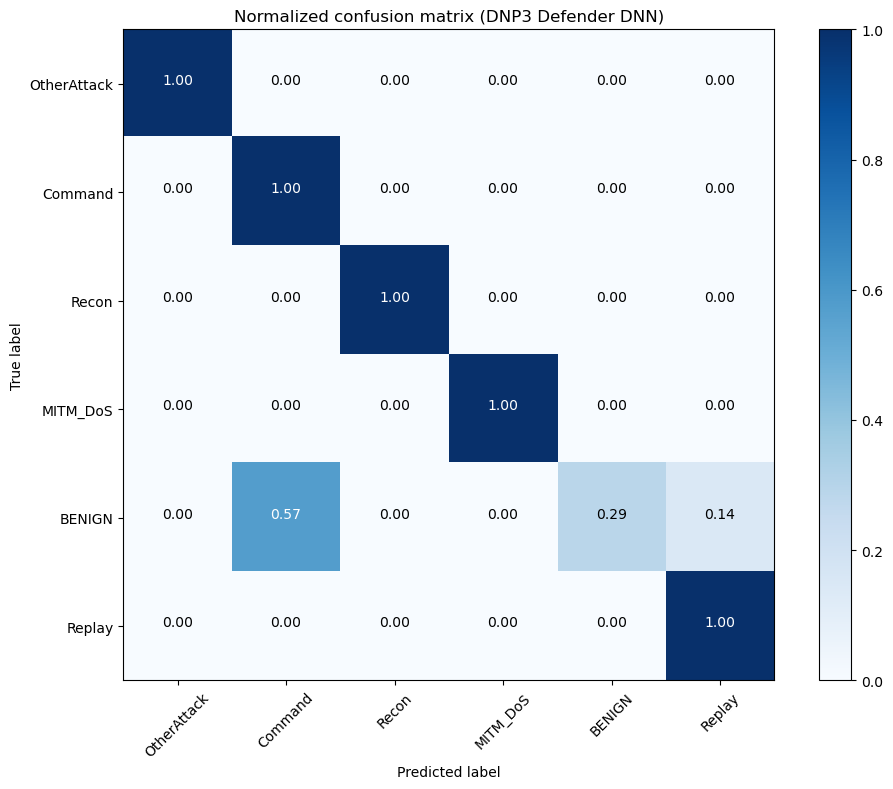

In [26]:
# Plot confusion matrix (normalized + raw)
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))
plot_confusion_matrix(cm, classes=env_test.attack_types, normalize=False,
                      title='Confusion matrix (DNP3 Defender DNN)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,8))
plot_confusion_matrix(cm, classes=env_test.attack_types, normalize=True,
                      title='Normalized confusion matrix (DNP3 Defender DNN)')
plt.tight_layout()
plt.show()


In [27]:
# Summary metrics
acc = accuracy_score(y_true, y_pred)
prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
gmean_macro = geometric_mean_score(y_true, y_pred, average='macro')

print(f"Accuracy:          {acc:.4f}"        )
print(f"Precision (macro): {prec_macro:.4f}" )
print(f"Recall    (macro): {rec_macro:.4f}"  )
print(f"F1        (macro): {f1_macro:.4f}"   )
print(f"G-Mean    (macro): {gmean_macro:.4f}")


Accuracy:          0.9219
Precision (macro): 0.9514
Recall    (macro): 0.8810
F1        (macro): 0.8811
G-Mean    (macro): 0.9285


In [24]:
# # ----------------------------
# # 6) Explainability for the defender (SHAP + SAGE)
# # ----------------------------
# # SHAP (recommended): uses a small background set to keep runtime manageable
# try:
#     import shap

#     # background and evaluation samples
#     background = X_tr[np.random.choice(X_tr.shape[0], size=min(256, X_tr.shape[0]), replace=False)]
#     sample = X_val[:min(512, X_val.shape[0])]

#     explainer = shap.Explainer(defender_dnn.model, background)
#     shap_values = explainer(sample)

#     # Global importance (bar)
#     shap.plots.bar(shap_values, max_display=20)
#     # Local/summary (beeswarm)
#     shap.plots.beeswarm(shap_values, max_display=20)

# except Exception as e:
#     print(f"SHAP explainability skipped (install shap or check TF/Keras compatibility): {e}")


In [20]:
# # ----------------------------
# # Explainability for the Defender (DNN) using SAGE (optional)
# # ----------------------------
# # Requires `sage-importance` (pip install sage-importance)

# import numpy as np

# try:
#     import sage

#     # Use the model from the TEST cell if present; otherwise load it
#     try:
#         _model = defender_dnn_model
#     except NameError:
#         import os, json
#         from keras.models import model_from_json
#         models_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_dnp3/"
#         with open(os.path.join(models_dir, "defender_dnn_model_dnp3.json"), "r") as f:
#             _json = json.load(f)
#         _model = model_from_json(_json)
#         _model.load_weights(os.path.join(models_dir, "defender_dnn_model_dnp3.weights.h5"))

#     # Use training arrays if available; else fall back to env_train full batch
#     try:
#         X_for_exp = X_tr
#         y_for_exp = ycoarse_tr
#         feature_names = list(X_train_df.columns)
#     except NameError:
#         # fallback: use env_test full, map fine->coarse
#         states_tmp, labels_tmp = env_test.get_full()
#         X_for_exp = states_tmp.to_numpy(dtype=np.float32)
#         fine_idx = np.argmax(labels_tmp.to_numpy(), axis=1)
#         fine_labels = labels_tmp.columns.to_numpy()[fine_idx]
#         coarse_labels = np.array([env_test.attack_map[lbl] for lbl in fine_labels])
#         y_for_exp = np.array([env_test.attack_types.index(t) for t in coarse_labels], dtype=int)
#         feature_names = list(states_tmp.columns)

#     # Prediction function must return probabilities over classes
#     def pred_fn(x):
#         x = np.asarray(x, dtype=np.float32)
#         return _model.predict(x, verbose=0)

#     # Background for the imputer
#     bg_n = min(512, X_for_exp.shape[0])
#     ex_n = min(2000, X_for_exp.shape[0])

#     bg_idx = np.random.choice(X_for_exp.shape[0], size=bg_n, replace=False)
#     ex_idx = np.random.choice(X_for_exp.shape[0], size=ex_n, replace=False)

#     X_bg = X_for_exp[bg_idx]
#     X_sage = X_for_exp[ex_idx]
#     y_sage = y_for_exp[ex_idx]

#     imputer = sage.MarginalImputer(pred_fn, X_bg)
#     estimator = sage.PermutationEstimator(imputer, loss='cross entropy')

#     imps = estimator(X_sage, y_sage, n_permutations=64)

#     # Plot top features
#     imps.plot(feature_names, max_features=20, title='Defender DNN SAGE (global importance)')

# except Exception as e:
#     print(f"SAGE explainability skipped (install sage-importance): {e}")
